<a href="https://colab.research.google.com/github/Giocrisrai/aprendizaje-refuerzo-duoc/blob/main/notebooks/10_taxi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# 10 · El taxi
**Machine Learning — Duoc UC**

Un taxi recorre una ciudad de 5 por 5, recoge a un pasajero y lo deja en su parada. Es un juego clásico de Gymnasium. En Colab se ve el tablero en texto.

El estado ya no es solo la casilla. También importa dónde está el pasajero y a qué parada va. Son 500 estados y 6 acciones: sur, norte, este, oeste, recoger y dejar. La tabla Q tiene 500 filas por 6 columnas. La actualización es la del notebook 01 y la del lago:

```
Q ← Q + α · (recompensa + γ · max Q(siguiente) − Q)
```

| Qué pasa | Recompensa | Dónde ya se vio |
|---|---|---|
| Cada paso | −1 | La casilla vacía del héroe, y el día que pasa sin cosechar |
| Recoger o dejar en el lugar equivocado | −10 | El zombi, un error caro |
| Dejar al pasajero en su parada | +20 | El trofeo, el premio que justifica la espera |

Un agente al azar acumula un número muy negativo: da vueltas y aprieta recoger donde no hay nadie. Después de entrenar, la política greedy termina en positivo.


In [1]:
#@title ⚙️ Configuración (en Colab instala Gymnasium y deja el juego listo)
import sys, subprocess

def _asegurar(paquete):
    try:
        return __import__(paquete)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])
        return __import__(paquete)

gymnasium = _asegurar("gymnasium")
numpy = _asegurar("numpy")
matplotlib = _asegurar("matplotlib")
print("Listo.", "gymnasium", gymnasium.__version__, "| numpy", numpy.__version__, "| matplotlib", matplotlib.__version__)


Listo. gymnasium 1.4.0 | numpy 2.5.4 | matplotlib 3.11.2


## El tablero

Las letras **R, G, Y, B** son las paradas. La letra **T** es el taxi. Las paredes (`|`) no se cruzan. Esta celda solo mira un episodio, sin aprender.


In [2]:
import re
import gymnasium as gym

def tablero(entorno):
    """Saca los colores y marca el taxi con T, para leerlo en Colab."""
    texto = entorno.render()
    escape = "\x1b"
    texto = re.sub(escape + r"\[43m." + escape + r"\[0m", "T", texto)
    texto = re.sub(escape + r"\[[0-9;]*m", "", texto)
    return texto

entorno = gym.make("Taxi-v4", render_mode="ansi")
estado, _ = entorno.reset(seed=0)
print(tablero(entorno))
print("T es el taxi. R, G, Y y B son las paradas.")
print("estado numérico:", estado, "| acciones: 0 sur, 1 norte, 2 este, 3 oeste, 4 recoger, 5 dejar")
entorno.close()


+---------+
|R: | : :G|
| : | : : |
| : : : : |
|T| : | : |
|Y| : |B: |
+---------+


T es el taxi. R, G, Y y B son las paradas.
estado numérico: 314 | acciones: 0 sur, 1 norte, 2 este, 3 oeste, 4 recoger, 5 dejar


## Entrenar y comparar con el azar

ε parte en 1, porque las 500 filas están en cero, y baja hasta 0,05. Jugar en greedy es otra cosa: ahí ε = 0 y se usa la acción de mayor Q. En el notebook 02 esa separación es la pregunta de la clase.


In [3]:
import numpy as np

def entrenar_taxi(episodios=6000, alpha=0.5, gamma=0.99, semilla=0):
    entorno = gym.make("Taxi-v4")
    rng = np.random.default_rng(semilla)
    n_estados, n_acciones = entorno.observation_space.n, entorno.action_space.n
    Q = np.zeros((n_estados, n_acciones))
    retornos = np.empty(episodios)
    for episodio in range(episodios):
        epsilon = max(0.05, 1.0 * (1 - episodio / (0.9 * episodios)))
        estado, _ = entorno.reset(seed=semilla + episodio)
        total = 0.0
        for _ in range(200):
            if rng.random() < epsilon:
                accion = int(rng.integers(n_acciones))
            else:
                accion = int(np.argmax(Q[estado]))
            siguiente, recompensa, termino, truncado, _ = entorno.step(accion)
            futuro = 0.0 if termino else gamma * float(Q[siguiente].max())
            Q[estado, accion] += alpha * (recompensa + futuro - Q[estado, accion])
            total += recompensa
            estado = siguiente
            if termino or truncado:
                break
        retornos[episodio] = total
    entorno.close()
    return Q, retornos

def jugar(Q, episodios, semilla, aleatorio=False):
    entorno = gym.make("Taxi-v4", render_mode="ansi")
    rng = np.random.default_rng(semilla)
    totales = []
    for k in range(episodios):
        estado, _ = entorno.reset(seed=semilla + k)
        total = 0.0
        for _ in range(200):
            if aleatorio or Q is None:
                accion = int(rng.integers(6))
            else:
                accion = int(np.argmax(Q[estado]))
            estado, recompensa, termino, truncado, _ = entorno.step(accion)
            total += recompensa
            if termino or truncado:
                break
        totales.append(total)
    entorno.close()
    return np.asarray(totales)

Q, retornos = entrenar_taxi()
azar = jugar(None, 30, semilla=20_000, aleatorio=True)
greedy = jugar(Q, 30, semilla=50_000)
print("retorno medio al azar: ", round(float(azar.mean()), 1))
print("retorno medio greedy:  ", round(float(greedy.mean()), 1))
print("el peor greedy de esas 30 salidas:", float(greedy.min()))


retorno medio al azar:  -772.4
retorno medio greedy:   8.2
el peor greedy de esas 30 salidas: 4.0


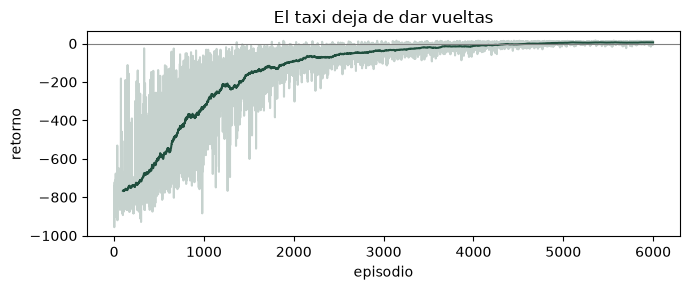

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 3))
plt.plot(retornos, color="#1f4e3d", alpha=0.25)
ventana = np.convolve(retornos, np.ones(100) / 100, mode="valid")
plt.plot(range(99, 99 + len(ventana)), ventana, color="#1f4e3d")
plt.axhline(0, color="gray", linewidth=0.8)
plt.xlabel("episodio")
plt.ylabel("retorno")
plt.title("El taxi deja de dar vueltas")
plt.tight_layout()
plt.show()


## Una carrera con la tabla ya lista

Se imprime el tablero al salir y al dejar al pasajero. Entre medio el taxi se mueve solo, con la acción de mayor Q. El retorno de esa carrera es el premio +20 menos 1 por cada paso, y menos 10 si intenta recoger o dejar mal.


In [5]:
entorno = gym.make("Taxi-v4", render_mode="ansi")
estado, _ = entorno.reset(seed=7)
print("al salir")
print(tablero(entorno))
total = 0.0
pasos = 0
while pasos < 200:
    accion = int(np.argmax(Q[estado]))
    estado, recompensa, termino, truncado, _ = entorno.step(accion)
    total += recompensa
    pasos += 1
    if termino or truncado:
        break
print(f"después de {pasos} acciones, retorno {total:.0f}")
print(tablero(entorno))
entorno.close()


al salir
+---------+
|R: | : :G|
| : | : : |
| : : : : |
|T| : | : |
|Y| : |B: |
+---------+


después de 11 acciones, retorno 10
+---------+
|R: | : :T|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)



## Qué se lleva de este juego

La ciudad es más grande que el lago y aun así cabe en una tabla: 500 por 6 son 3000 números. Cada paso cobra −1, igual que la casilla vacía del héroe. El premio llega al final, igual que el trofeo. Si nadie cobra el paso, apurar cualquier entrega parecería gratis. Ese es el mecanismo del notebook 03 cuando la camioneta se vende el día 0.

El notebook 11 corta un estado continuo en cajas, porque un ángulo con decimales no puede ser la fila de una tabla.
